In [1]:
import tomllib

import matplotlib.pyplot as plt
import numpy as np
import plt_config  # noqa: F401
import seaborn as sns

In [2]:
with open("../config.toml", "rb") as f:
    cfg = tomllib.load(f)
curr_module = "04"
num_particles = cfg[curr_module]["num_particles"]
low_perc = cfg[curr_module]["low_perc"]
high_perc = cfg[curr_module]["high_perc"]
CI = cfg[curr_module]["CI"]
dev_perc = cfg[curr_module]["dev_perc"]
deviations = cfg[curr_module]["deviations"]
num_patients = cfg[curr_module]["num_patients"]
num_deviations = len(deviations)

# Introduction 
Within this file, different methods of parameter estimation will be implemented and compared to predict the Insulin Sensitivity $\, SI$ in patients

In [3]:
try:
    SI_ests = np.load(
        "../scripts/saved_variables/module4/SI_ests_integral_static_04.npy"
    )
    SI_errs = np.load(
        "../scripts/saved_variables/module4/SI_errs_integral_static_mse_04.npy"
    )
    SI_errs_int_static = SI_errs.copy()
    SI_true_arr = np.load(
        "../scripts/saved_variables/module4/SI_true_arr_integral_static_04.npy"
    )
    print("Loaded variables")

except FileNotFoundError:
    print("Run 04_Parameter_estimation_integral.py")

Loaded variables


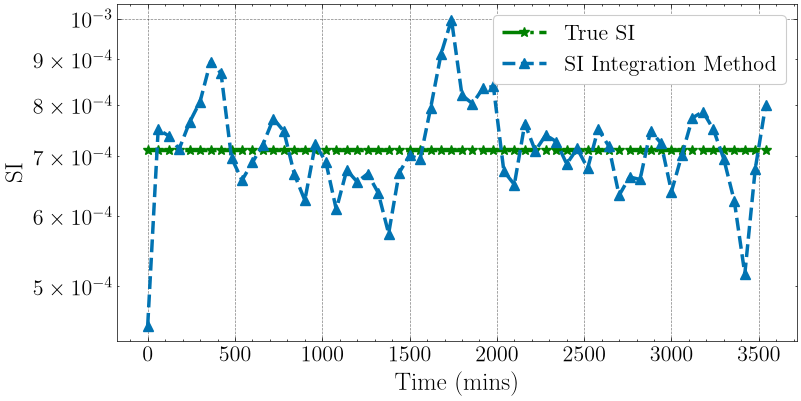

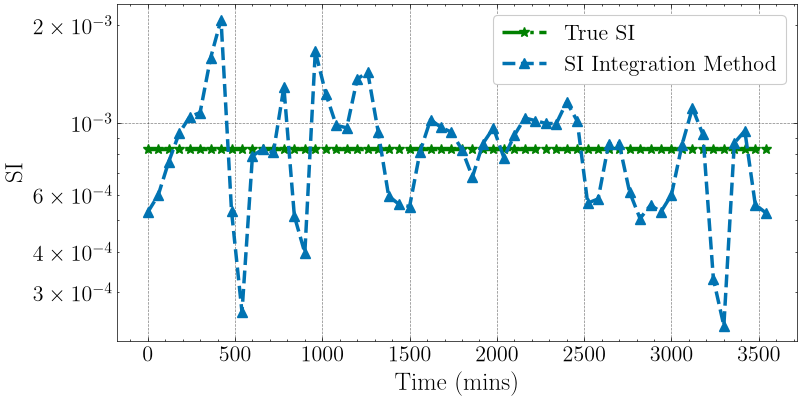

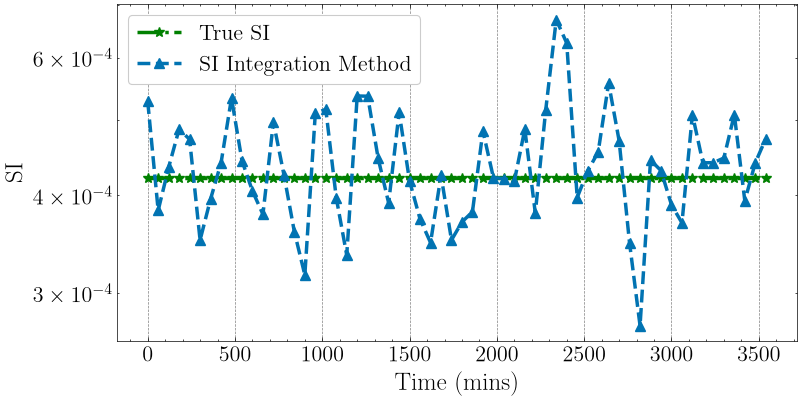

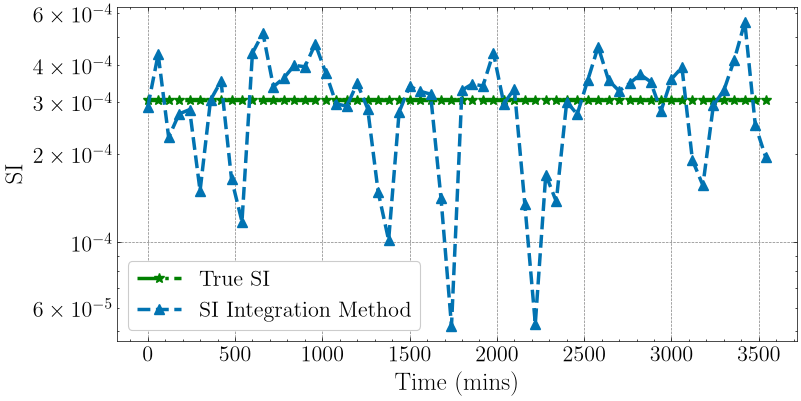

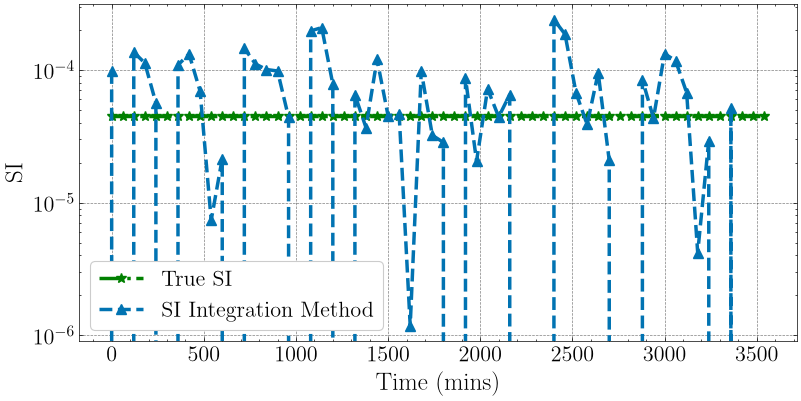

In [4]:
time = np.arange(SI_true_arr.shape[1]) * 60
palette = sns.color_palette("colorblind", 1)

for i in range(5):
    fig, ax = plt.subplots(figsize=(8, 4))
    true_SI = SI_true_arr[i, :]
    ax.semilogy(
        time, true_SI, linestyle="-.", marker="*", color="green", label="True SI"
    )
    est = SI_ests[i, :]
    ax.semilogy(
        time,
        est,
        linestyle="--",
        marker="^",
        color=palette[0],
        label="SI Integration Method",
    )
    ax.set_xlabel("Time (mins)")
    ax.set_ylabel("SI")
    ax.legend()

In [5]:
total_mse = np.average(SI_errs, axis=(0, 1))
print("Total MSE: ", total_mse)

Total MSE:  1.2907651377851101e-08


In [6]:
try:
    SI_ests = np.load("../scripts/saved_variables/module4/SI_ests_integral_vary_04.npy")
    SI_errs = np.load(
        "../scripts/saved_variables/module4/SI_errs_integral_vary_mse_04.npy"
    )
    SI_true_arr = np.load(
        "../scripts/saved_variables/module4/SI_true_arr_integral_vary_04.npy"
    )
    print("Loaded variables")
except FileNotFoundError:
    print("Run 04_Parameter_estimation_integral_vary.py")

Loaded variables


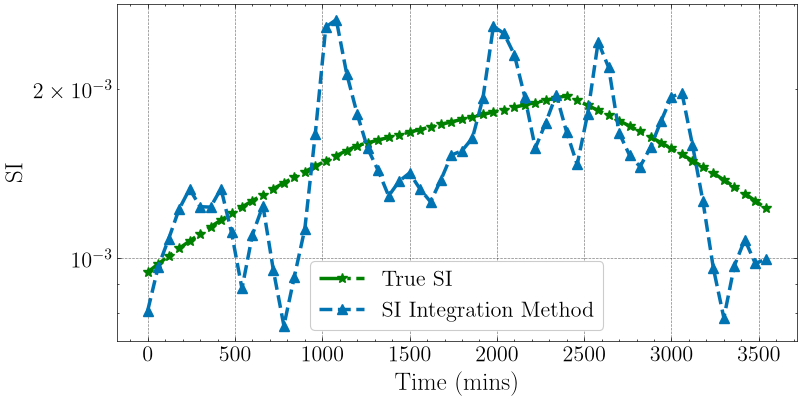

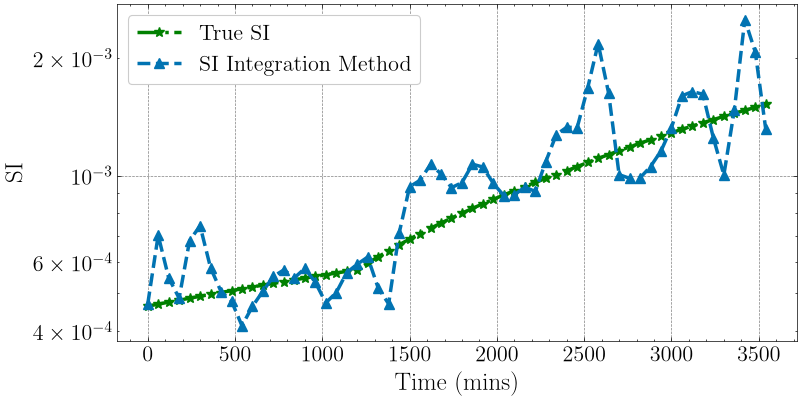

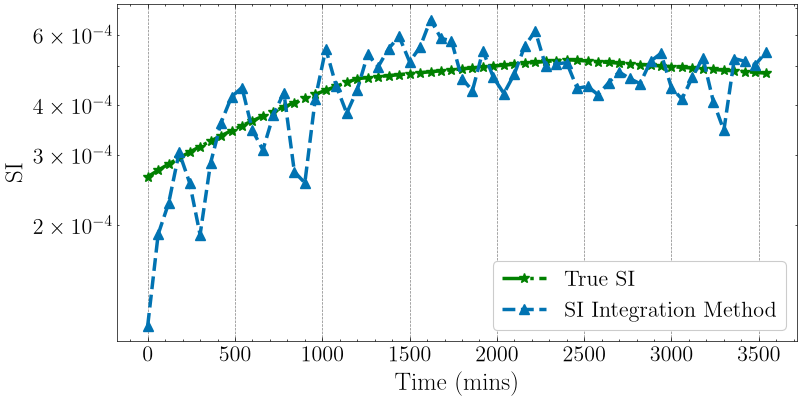

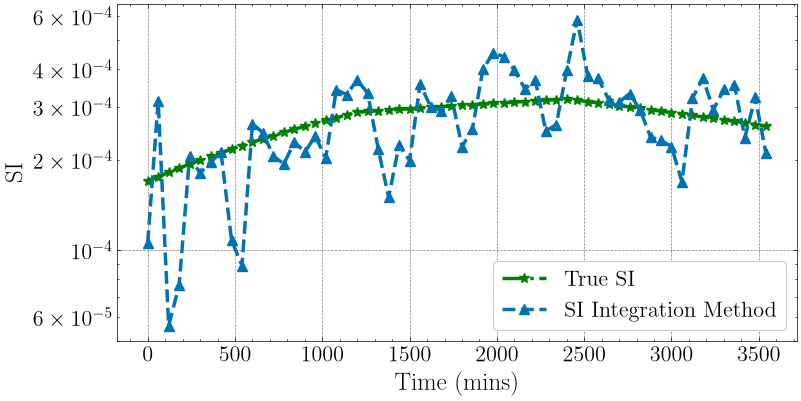

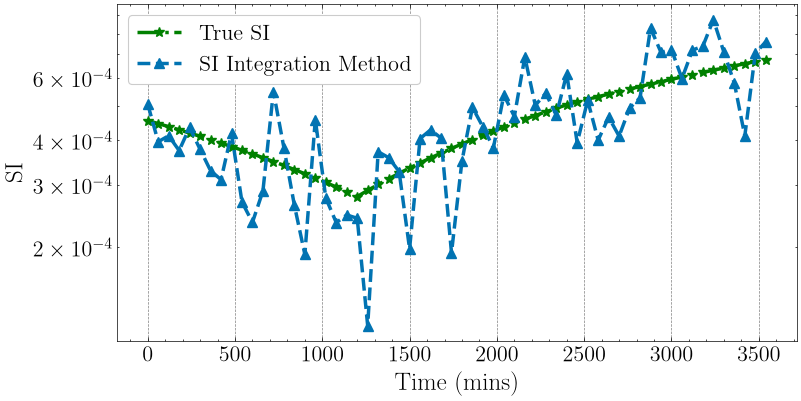

In [7]:
for i in range(5):
    fig, ax = plt.subplots(figsize=(8, 4))
    true_SI = SI_true_arr[i, :]
    ax.semilogy(
        time, true_SI, linestyle="-.", marker="*", color="green", label="True SI"
    )
    est = SI_ests[i, :]
    ax.semilogy(
        time,
        est,
        linestyle="--",
        marker="^",
        color=palette[0],
        label="SI Integration Method",
    )
    ax.set_xlabel("Time (mins)")
    ax.set_ylabel("SI")
    ax.legend()

In [8]:
total_mse = np.mean(SI_errs, axis=(0, 1))
print("Total MSE: ", total_mse)

Total MSE:  4.4878648261726644e-08


In [9]:
try:
    SI_ests = np.load(
        "../scripts/saved_variables/module4/SI_ests_augment_static_04.npy"
    )
    SI_errs = np.load(
        "../scripts/saved_variables/module4/SI_errs_augment_static_mse_04.npy"
    )
    SI_true_arr = np.load(
        "../scripts/saved_variables/module4/SI_true_arr_augment_static_04.npy"
    )
    # G_true_arr = np.load("../scripts/saved_variables/module4/G_true_arr_augment_static_04.npy")
    # states = np.load("../scripts/saved_variables/module4/states_augment_static_04.npy")
    print("Loaded variables")
except FileNotFoundError:
    print("Run 04_Paramater_estimation_augment.py")

Loaded variables


SI process noise of 8e-4

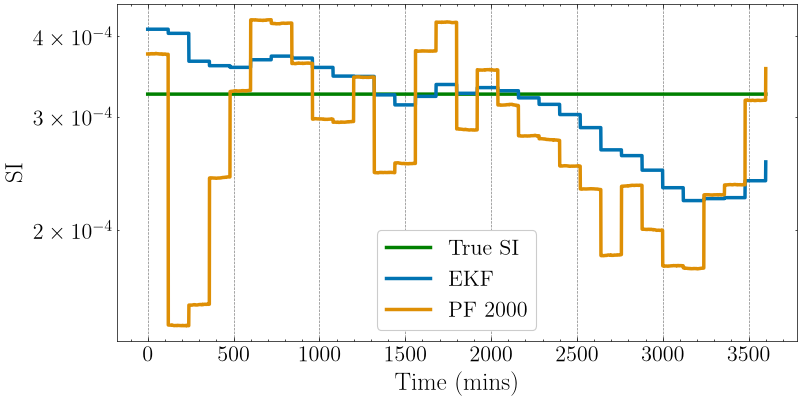

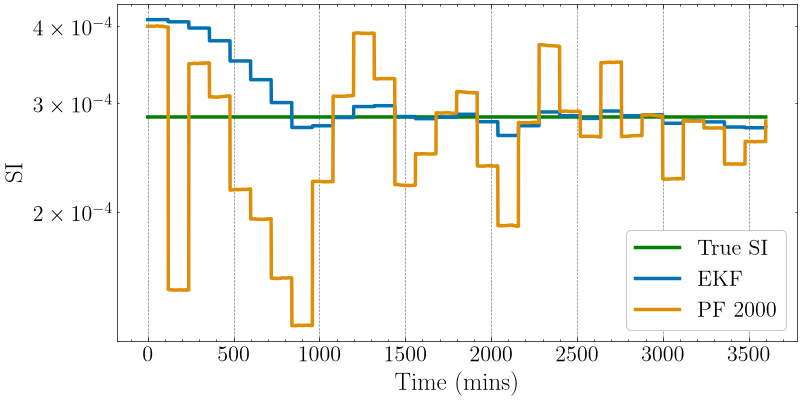

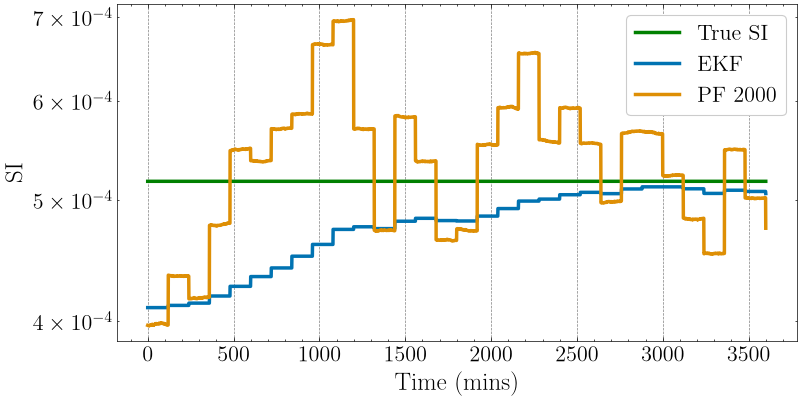

In [10]:
filters = ["EKF"]
pfs = [f"PF {particles}" for particles in num_particles]
filters.extend(pfs)
time = np.arange(SI_true_arr.shape[1])
num_filters = len(filters)
palette = sns.color_palette("colorblind", num_filters + 1)

for i in range(3):
    fig, ax = plt.subplots(figsize=(8, 4), sharex=True)
    true_SI = SI_true_arr[i, :]
    ax.semilogy(time, true_SI, color="green", label="True SI")
    for k in range(num_filters):
        patient = i
        est = SI_ests[k, i, :]
        m = np.isfinite(est)
        ax.semilogy(
            time[m], est[m], linestyle="-", color=palette[k], label=f"{filters[k]}"
        )
        ax.set_ylabel("SI")
        ax.legend()

    ax.set_xlabel("Time (mins)")

In [11]:
mse = np.nanmean(SI_errs, axis=(1, 2))
std = np.nanstd(SI_errs, axis=(1, 2))

print("Mean MSE: ", mse)
print("std: ", std)

# mse = np.nanmean(SI_errs, axis=(0, 2, 3))
# std = np.nanstd(SI_errs, axis=(0, 2, 3))
# print("Average Mean MSE: ", mse)
# print("Average std: ", std)

invalid_runs = (~np.isfinite(SI_ests[0, :, :]).all(axis=(-1))).sum()
print("ekf failure rate: ", invalid_runs / (100 * num_deviations))

Mean MSE:  [5.62151832e-08 1.49459958e-08]
std:  [3.30287849e-07 1.03965577e-07]
ekf failure rate:  0.0


# SI piecewise 

In [12]:
try:
    SI_ests = np.load("../scripts/saved_variables/module4/SI_ests_augment_vary_04.npy")
    # SI_ests_2500 = np.load("../scripts/saved_variables/module4/SI_ests_augment_vary_new_04.npy")
    SI_errs = np.load(
        "../scripts/saved_variables/module4/SI_errs_augment_vary_mse_04.npy"
    )
    # SI_errs_2500 = np.load("../scripts/saved_variables/module4/SI_errs_augment_vary_new_04.npy")
    SI_true_arr = np.load(
        "../scripts/saved_variables/module4/SI_true_arr_augment_vary_04.npy"
    )
    print("Loaded variables")
except FileNotFoundError:
    print("Run 04_Paramater_estimation_augment_vary.py")

Loaded variables


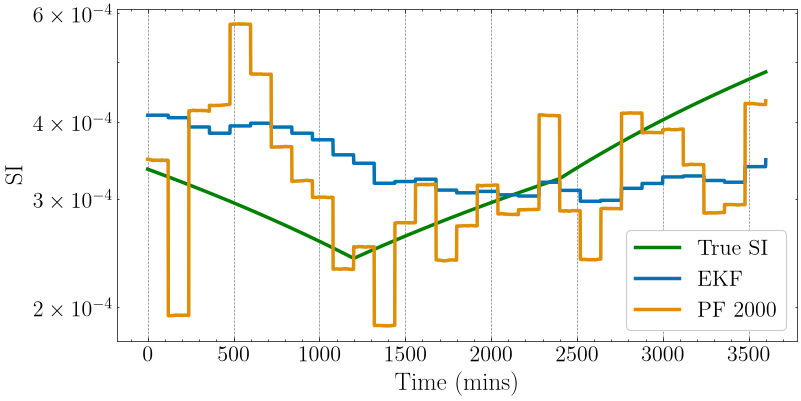

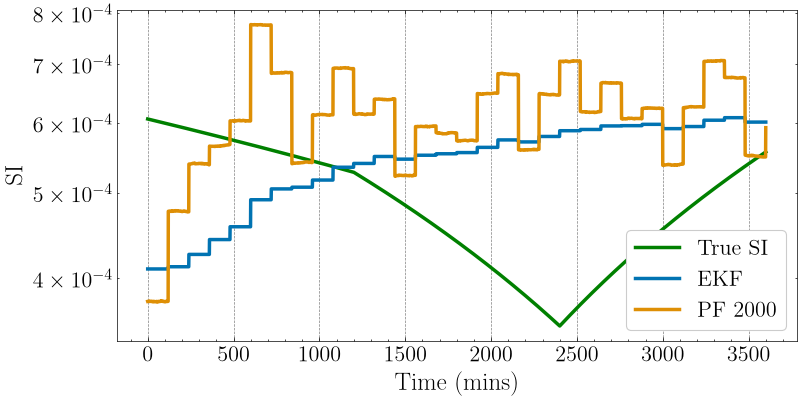

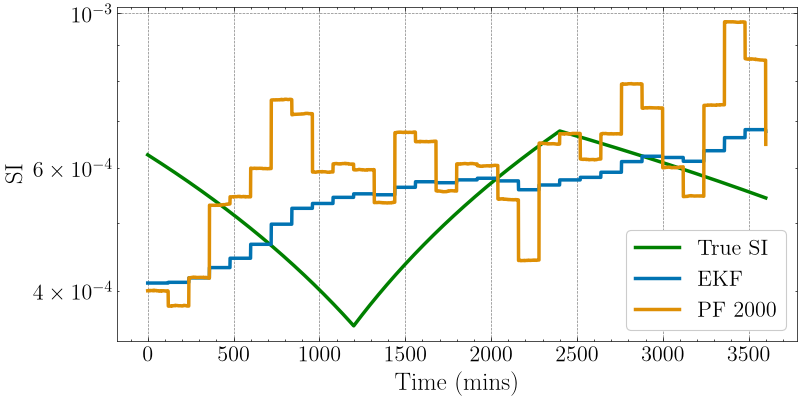

In [13]:
time = np.arange(SI_true_arr.shape[1])
filters = ["EKF"]
pfs = [f"PF {particles}" for particles in num_particles]
filters.extend(pfs)
num_filters = len(filters)
palette = sns.color_palette("colorblind", num_filters)

for i in range(3):
    fig, ax = plt.subplots(figsize=(8, 4), sharex=True)
    # for j in range(num_deviations):
    true_SI = SI_true_arr[i, :]
    m_true = np.isfinite(true_SI)
    ax.semilogy(time[m_true], true_SI[m_true], color="green", label="True SI")

    for k in range(num_filters):
        est = SI_ests[k, i, :]
        m = np.isfinite(est)
        ax.semilogy(
            time[m], est[m], linestyle="-", color=palette[k], label=f"{filters[k]}"
        )

    ax.set_ylabel("SI")
    ax.legend()
    ax.set_xlabel("Time (mins)")

In [14]:
mse = np.nanmean(SI_errs, axis=(1, 2))
std = np.nanstd(SI_errs, axis=(1, 2))
print("Mean MSE: ", mse)
print("std: ", std)

# mse = np.nanmean(SI_errs, axis=(0, 2, 3))
# std = np.nanstd(SI_errs, axis=(0, 2, 3))
# print("Average Mean MSE: ", mse)
# print("Average std: ", std)

invalid_runs = (~np.isfinite(SI_ests[0, :, :]).all(axis=(-1))).sum()
print("ekf failure rate: ", invalid_runs / (100 * num_deviations))

Mean MSE:  [1.43440852e-07 1.13837277e-07]
std:  [4.23039107e-07 3.30721569e-07]
ekf failure rate:  0.0


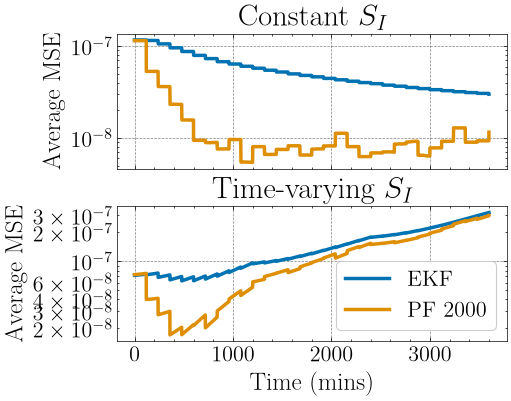

In [15]:
SI_errs_augment_static = np.load(
    "../scripts/saved_variables/module4/SI_errs_augment_static_mse_04.npy"
)
SI_errs_augment_static = np.nanmean(SI_errs_augment_static, axis=1)
SI_errs_augment_vary = np.load(
    "../scripts/saved_variables/module4/SI_errs_augment_vary_mse_04.npy"
)
SI_errs_augment_vary = np.nanmean(SI_errs_augment_vary, axis=1)

SI_errs_integral_static = np.load(
    "../scripts/saved_variables/module4/SI_errs_integral_static_mse_04.npy"
)
int_time = np.arange(SI_errs_integral_static.shape[1]) * 60
SI_errs_integral_static = np.mean(SI_errs_integral_static, axis=0)

SI_errs_integral_vary = np.load(
    "../scripts/saved_variables/module4/SI_errs_integral_vary_mse_04.npy"
)
SI_errs_integral_vary = np.mean(SI_errs_integral_vary, axis=0)


palette = sns.color_palette("colorblind", 3)
fig, ax = plt.subplots(2, 1, figsize=(5.1, 4), sharex=True)

ax[0].plot(time, SI_errs_augment_static[0, :], color=palette[0], label="EKF")
ax[0].plot(time, SI_errs_augment_static[1, :], color=palette[1], label="PF 2000")
# ax[0].plot(
#     int_time,
#     SI_errs_integral_static,
#     color=palette[2],
#     label="Integral Method",
#     linestyle="--",
#     marker="^",
# )
ax[0].set_yscale("log")
ax[0].set_ylabel("Average MSE")
# ax[0].legend(loc="best")
ax[0].set_title(r"Constant $S_I$")
ax[1].plot(time, SI_errs_augment_vary[0, :], color=palette[0], label="EKF")
ax[1].plot(time, SI_errs_augment_vary[1, :], color=palette[1], label="PF 2000")
# ax[1].plot(
#     int_time,
#     SI_errs_integral_vary,
#     color=palette[2],
#     label="Integral Method",
#     linestyle="--",
#     marker="^",
# )
ax[1].set_yscale("log")
ax[1].set_xlabel("Time (mins)")
ax[1].set_ylabel("Average MSE")
ax[1].legend()
ax[1].set_title(r"Time-varying $S_I$")
fig.savefig("figures/5_10.pdf", format="pdf")